# Mock-pipeline validation

This notebook demonstrates the complete BayMorph mock workflow using the public pipeline API.

The simulation, preparation, PSF, fitting, and diagnostic settings are stored in `configs/mock_pipeline.yaml`.

In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd

from baymorph import (
    load_resolved_config,
    make_observation_from_config,
    run_image_preparation,
    run_real_fit,
)

In [2]:
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "configs").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

os.chdir(PROJECT_ROOT)

CONFIG_PATH = PROJECT_ROOT / "configs" / "mock_pipeline.yaml"
config = load_resolved_config(CONFIG_PATH)

In [3]:
observation = make_observation_from_config(config)
image_path = Path(config["data"]["image_path"])
image_path.parent.mkdir(parents=True, exist_ok=True)
observation.to_fits(image_path, overwrite=config["outputs"]["overwrite"])

print(f"Mock FITS written to: {image_path}")

Mock FITS written to: runs/mock_pipeline/input/mock_pipeline.fits


In [4]:
preparation = run_image_preparation(config)
fit = run_real_fit(config)

pd.DataFrame(
    [
        {
            "estimated_background": preparation.background,
            "estimated_noise": np.nanmedian(preparation.noise),
            "reduced_chi2": fit.reduced_chi2,
        }
    ]
)

iter: 19293 | +300 | bound: 64 | nc: 1 | ncall: 529202 | eff(%):  3.704 | loglstar:   -inf < -25761.322 <    inf | logz: -25820.920 +/-  0.428 | dlogz:  0.000 >  0.010                               

,estimated_background,estimated_noise,reduced_chi2
0,5.337539,3.06152,0.975809


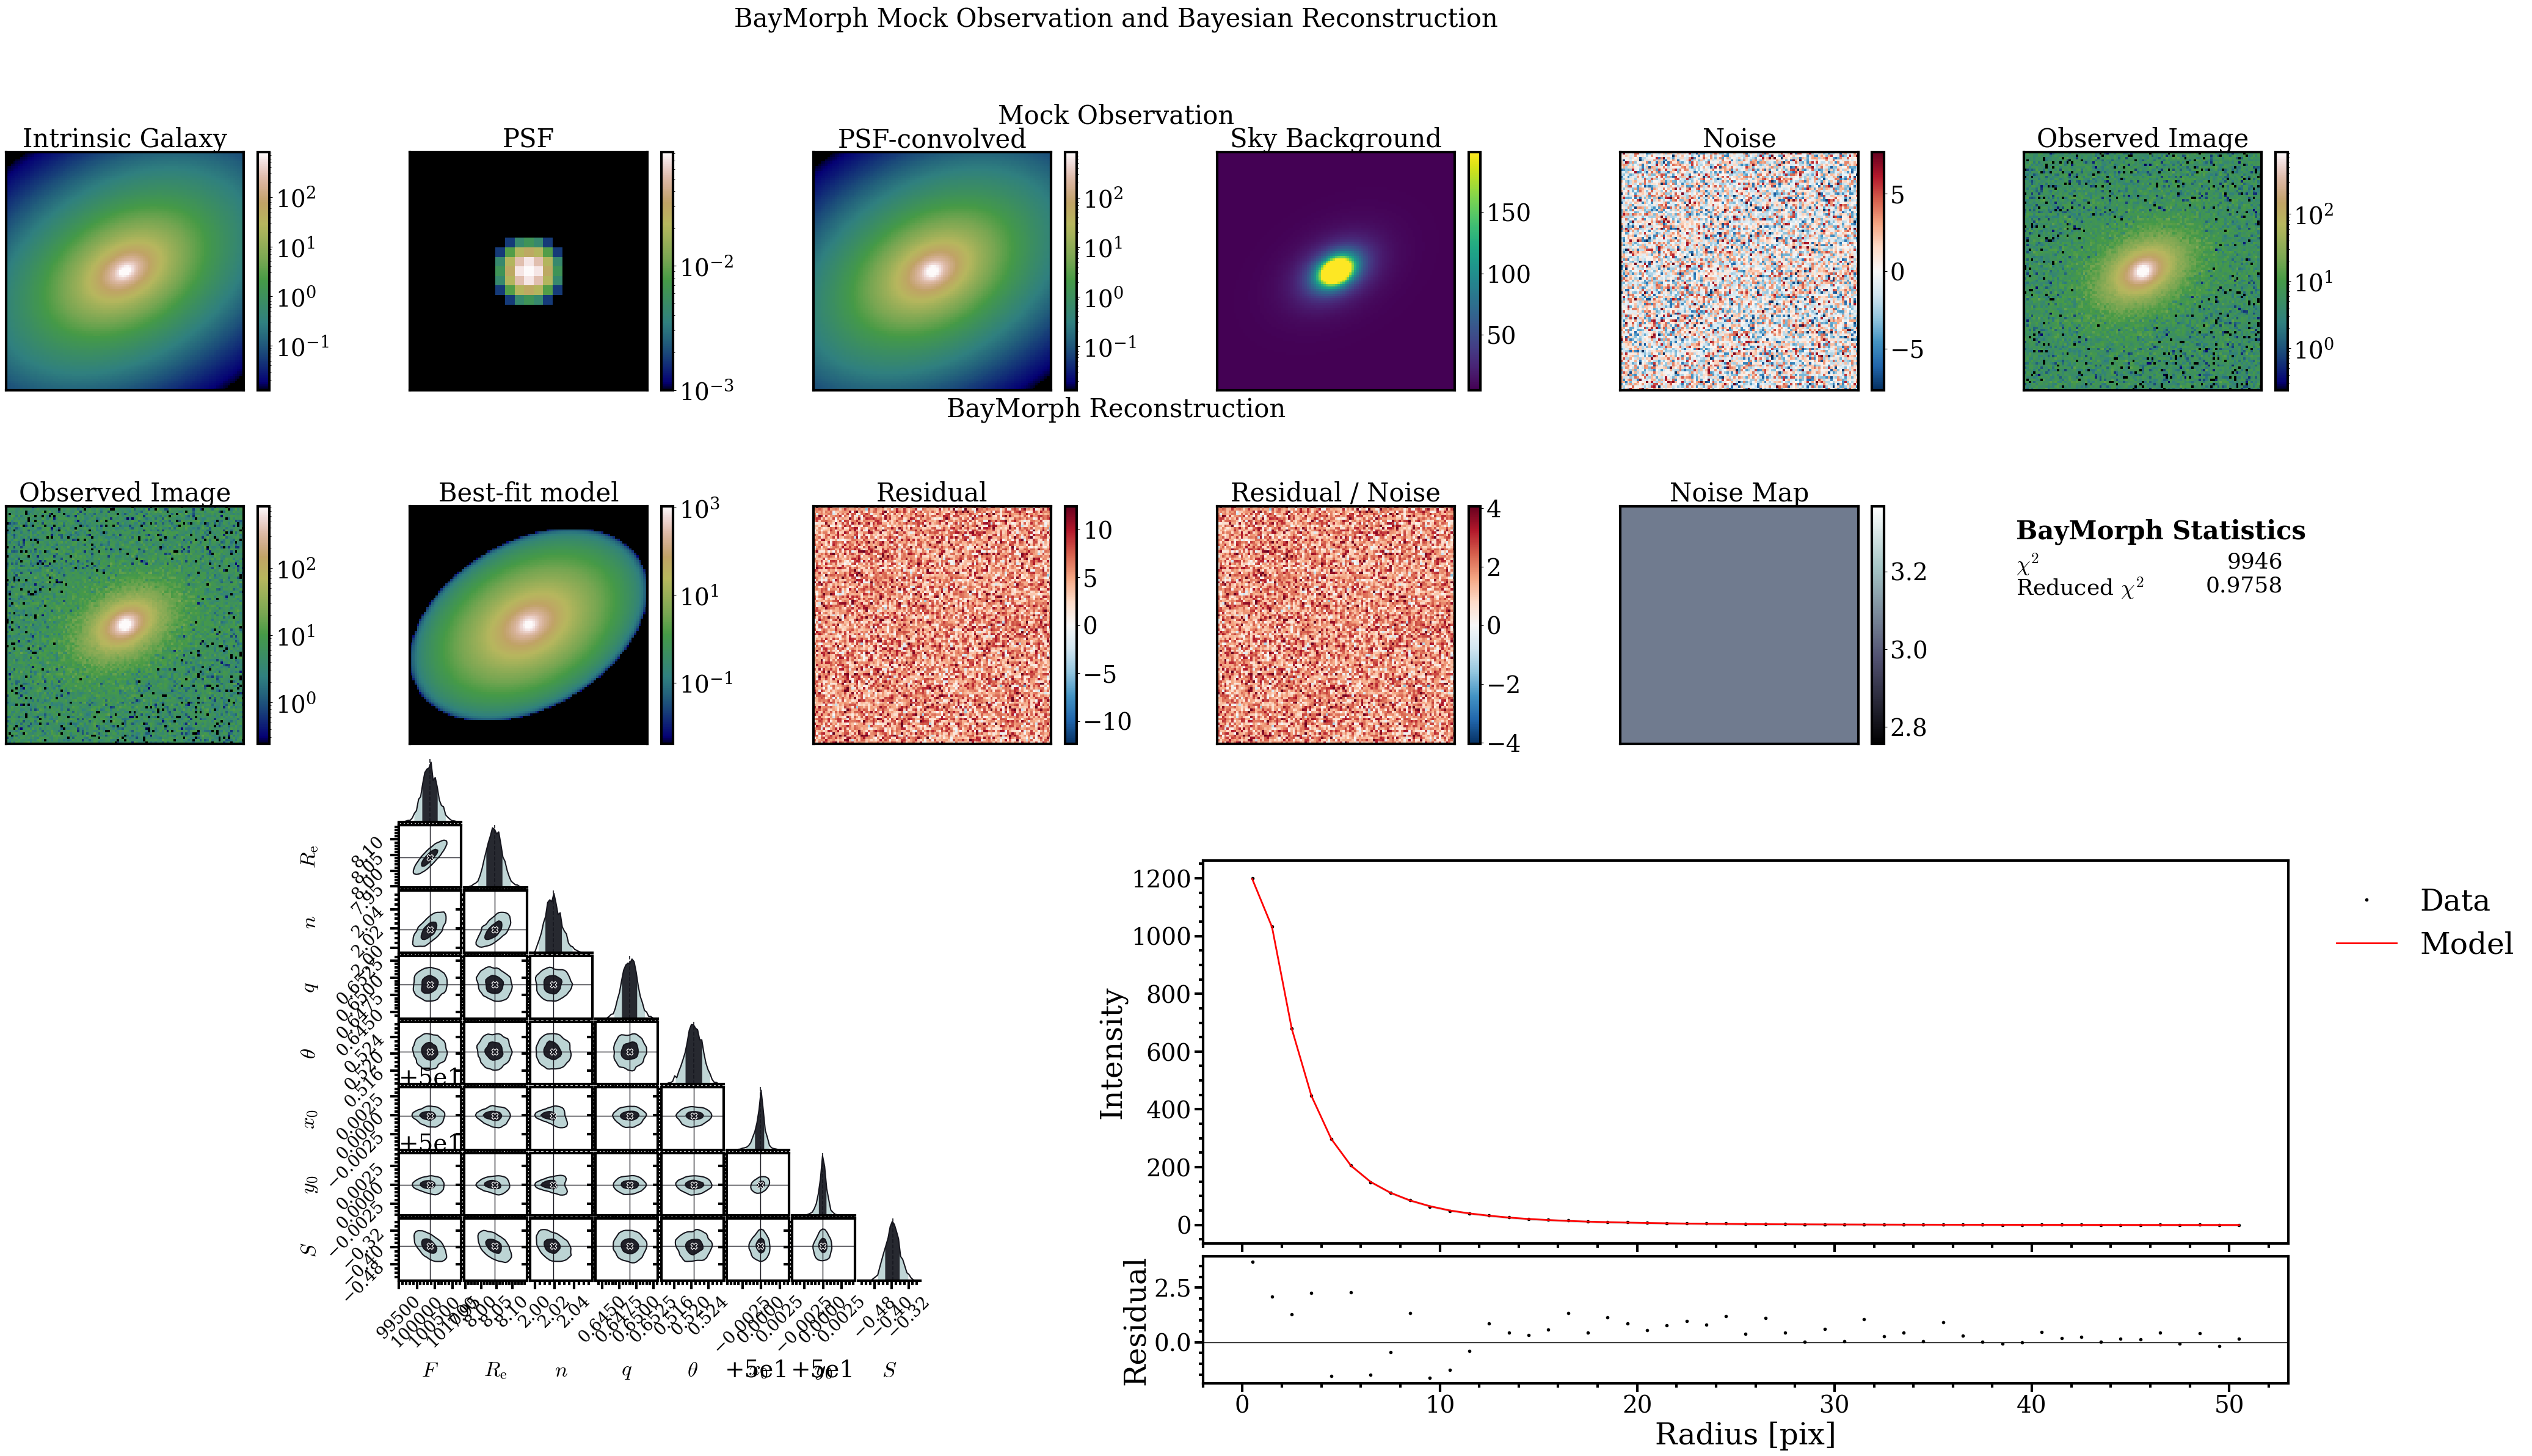

(<Figure size 4000x2400 with 90 Axes>,
 array([[<Axes: title={'center': 'Intrinsic Galaxy'}>,
         <Axes: title={'center': 'PSF'}>,
         <Axes: title={'center': 'PSF-convolved'}>,
         <Axes: title={'center': 'Sky Background'}>,
         <Axes: title={'center': 'Noise'}>,
         <Axes: title={'center': 'Observed Image'}>],
        [<Axes: title={'center': 'Observed Image'}>,
         <Axes: title={'center': 'Best-fit model'}>,
         <Axes: title={'center': 'Residual'}>,
         <Axes: title={'center': 'Residual / Noise'}>,
         <Axes: title={'center': 'Noise Map'}>, <Axes: >]], dtype=object))

In [5]:
fit.report(observation)

(<Figure size 1500x1500 with 64 Axes>,
 array([[<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
         <Axes: >, <Axes: >],
        [<Axes: ylabel='$R_{\\rm e}$'>, <Axes: >, <Axes: >, <Axes: >,
         <Axes: >, <Axes: >, <Axes: >, <Axes: >],
        [<Axes: ylabel='$n$'>, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
         <Axes: >, <Axes: >, <Axes: >],
        [<Axes: ylabel='$q$'>, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
         <Axes: >, <Axes: >, <Axes: >],
        [<Axes: ylabel='$\\theta$'>, <Axes: >, <Axes: >, <Axes: >,
         <Axes: >, <Axes: >, <Axes: >, <Axes: >],
        [<Axes: ylabel='$x_0$'>, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
         <Axes: >, <Axes: >, <Axes: >],
        [<Axes: ylabel='$y_0$'>, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
         <Axes: >, <Axes: >, <Axes: >],
        [<Axes: xlabel='$F$', ylabel='$S$'>,
         <Axes: xlabel='$R_{\\rm e}$'>, <Axes: xlabel='$n$'>,
         <Axes: xlabel='$q$'>, <Axes: xlabel='$\\theta$'>,
         <A

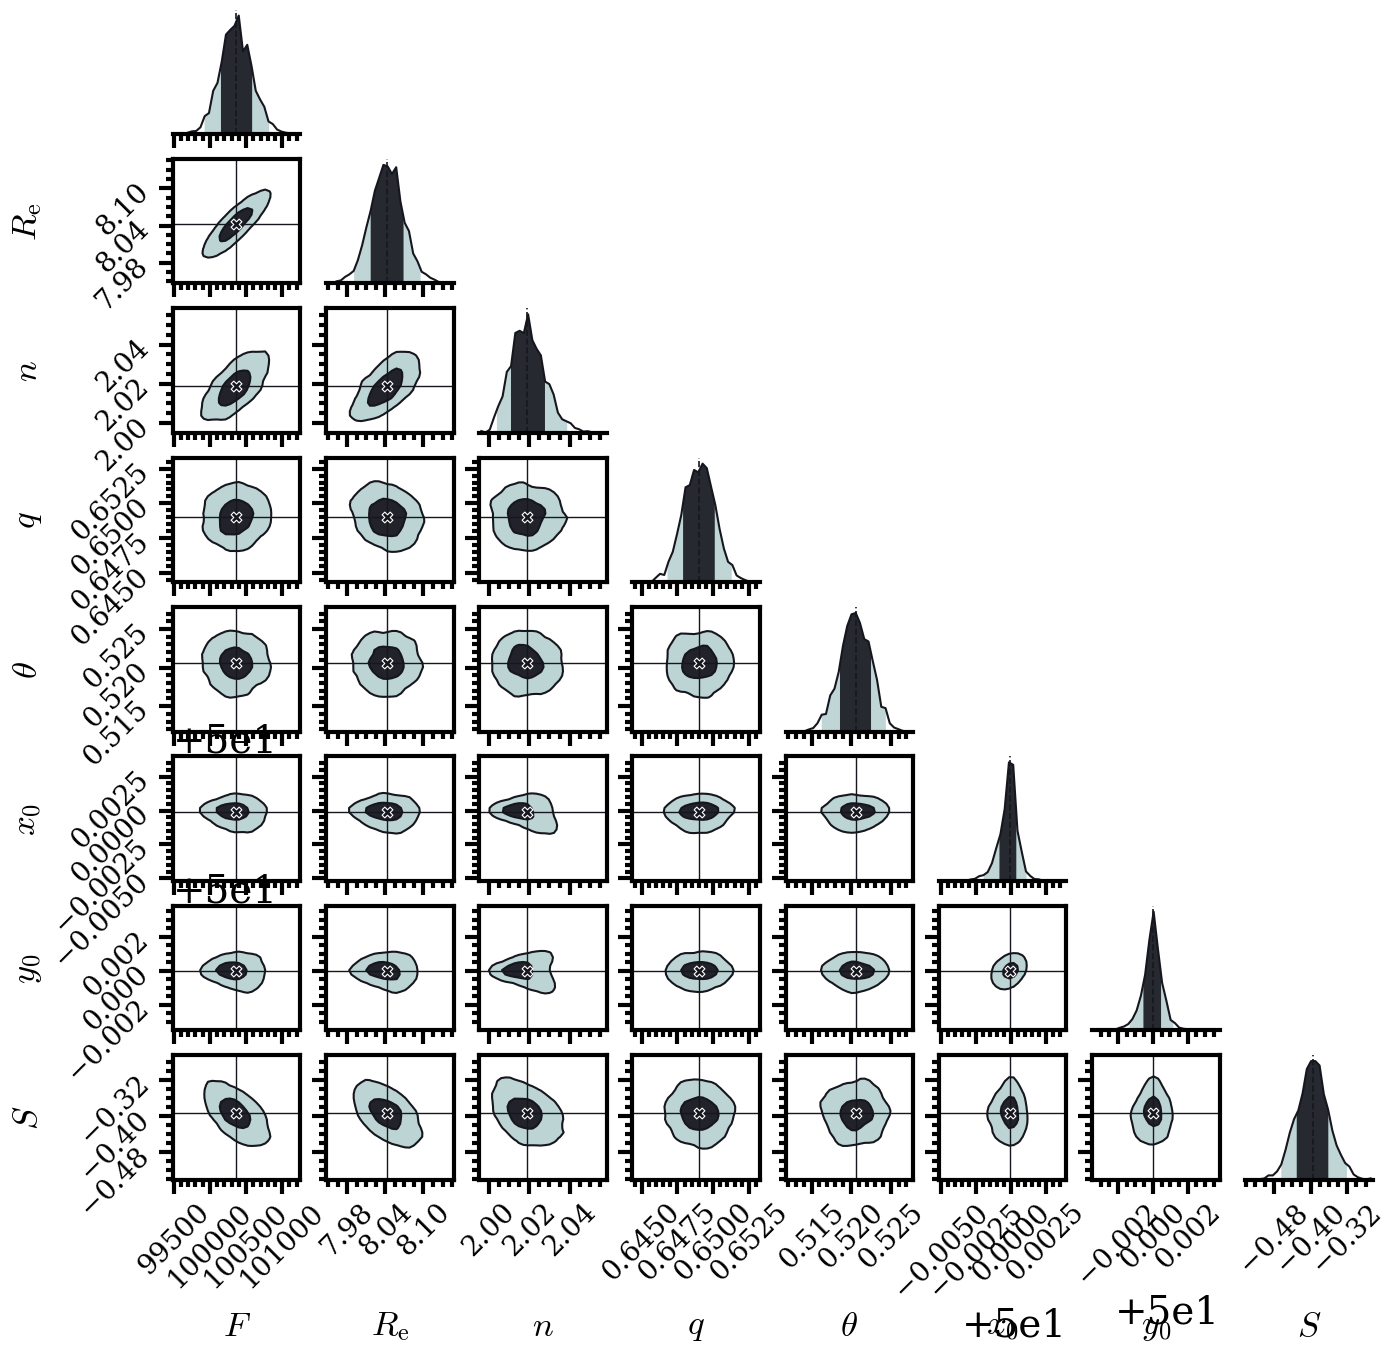

In [6]:
fit.corner()

(<Figure size 1500x1500 with 2 Axes>,
 (<Axes: ylabel='Intensity'>,
  <Axes: xlabel='Radius [pix]', ylabel='Residual'>))

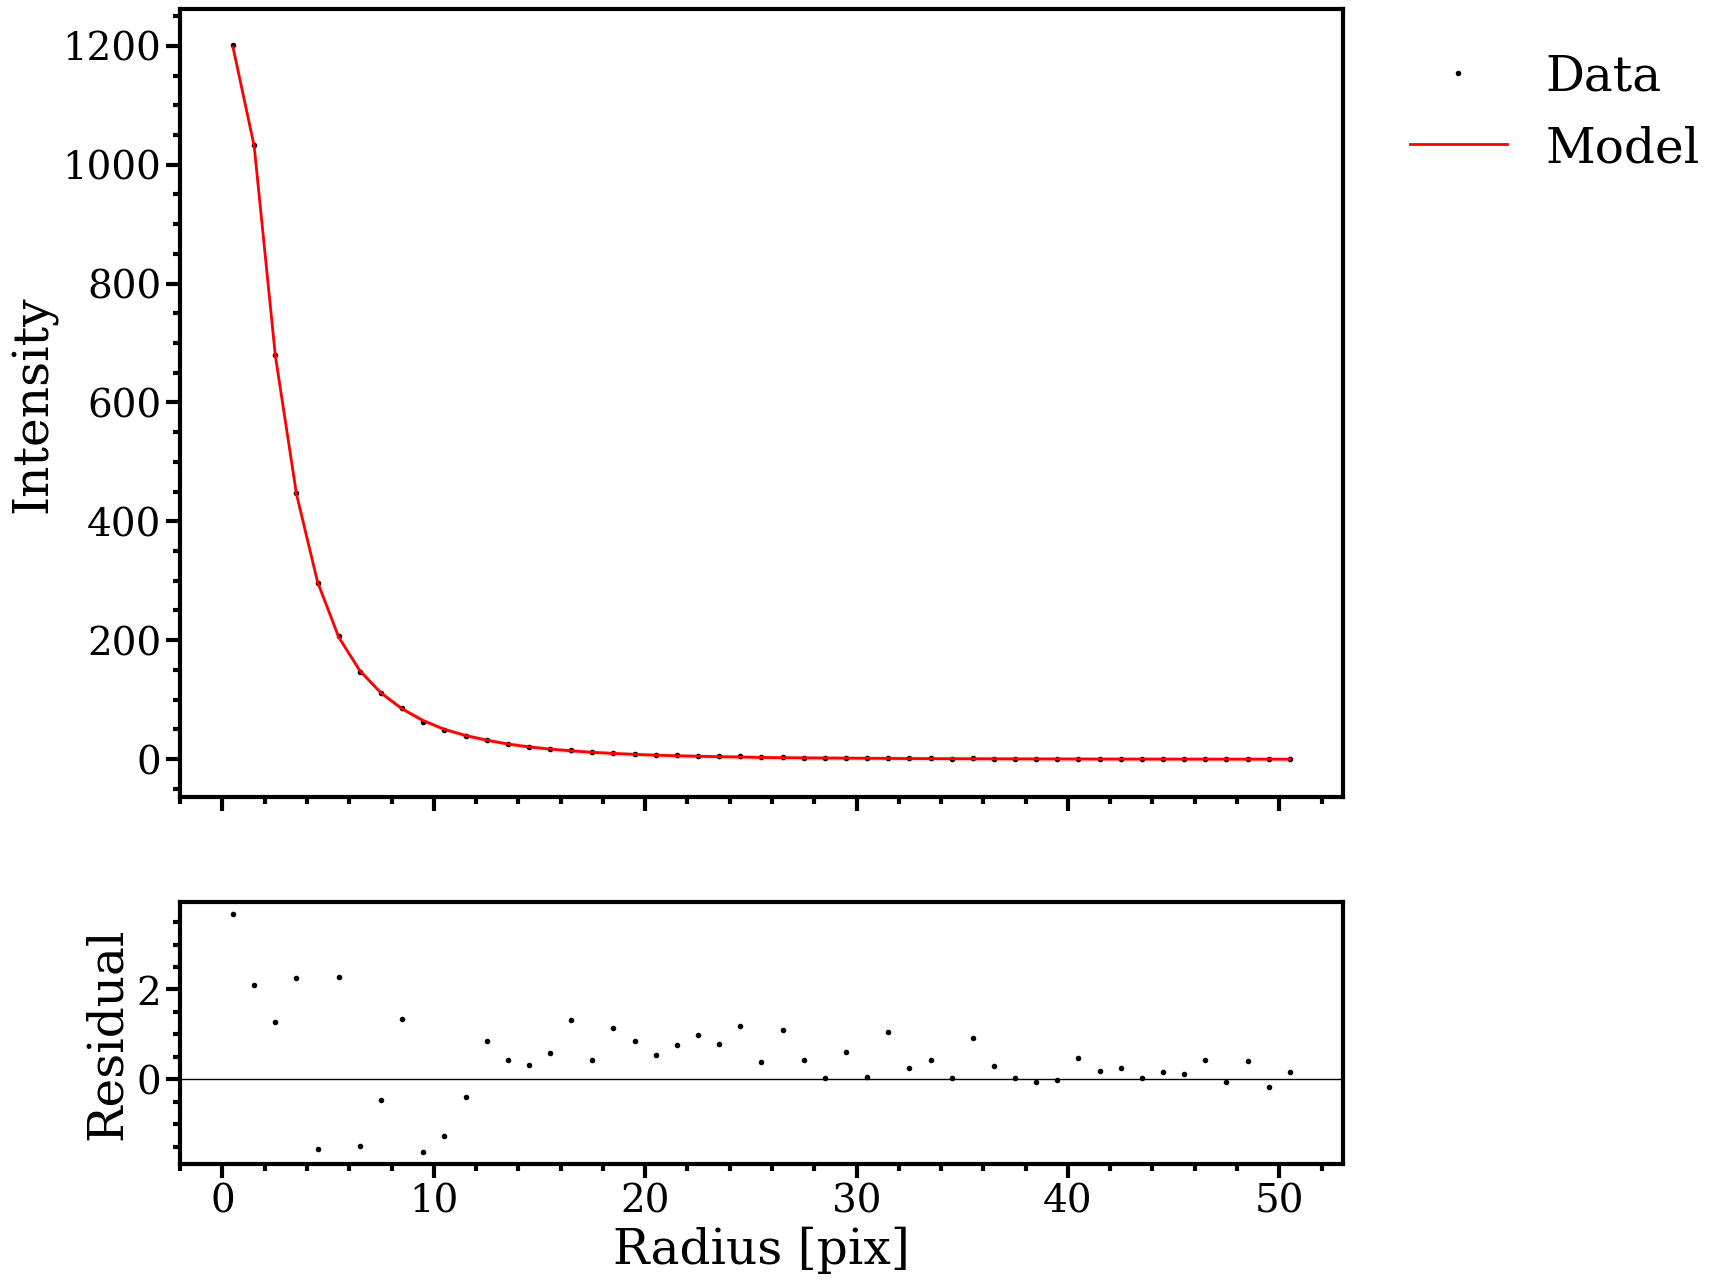

In [7]:
fit.radial_profile()

## Summary

The notebook generates a controlled mock image, prepares it as an observed FITS file, fits the configured model, and displays the BayMorph report and diagnostics.